# CaSR v3.2 → Vancouver training pair (v2 — properly sized grid)

Fixes the small-grid problem in v1. v1 used a 0.5°×1.0° box → an 8×9 patch → a 6×9
fine target, far too small for a meaningful variogram. This version:

- **Large region.** A configurable box (default ~6°) around Vancouver so the fine grid
  is ~80×80+, matching the patch sizes in the downscaling literature.
- **`tas` (1.5 m MEAN temperature)** by default — v1 auto-picked `tasmin` (daily min)
  because the scorer tied and took the first alphabetically.
- **Optional 16×16 patch tiling** (sliding window, stride 8), exactly as the AOD
  downscaling paper does — turns one region into thousands of training samples and
  increases effective sample size.
- Still **coarsen-onto-itself** (one dataset, no cross-grid regridding).

Everything else — OPeNDAP crop-before-load, rotated-grid masking, the `.npz` output
format your U-Net notebook reads — is unchanged from v1.

## 0. Environment

In [1]:
import sys
!{sys.executable} -m pip install -q xarray pydap netcdf4 dask numpy

## 1. Open the dataset over OPeNDAP

In [1]:
import numpy as np
import xarray as xr

url = "https://pavics.ouranos.ca/twitcher/ows/proxy/thredds/dodsC/datasets/reanalyses/day_NAM_GovCan_CaSR_v32_1968-2024.ncml"

# Open dataset. For hourly data, we suggest using the following chunking pattern: dict(time=1461, rlon=50, rlat=50)  : 4 year chunks in time dim
ds = xr.open_dataset(url, chunks=dict(time=1461, rlon=50, rlat=50))
ds

<xarray.Dataset> Size: 2TB
Dimensions:       (rlat: 778, rlon: 706, time: 20820)
Coordinates:
  * rlat          (rlat) float32 3kB -44.1 -44.01 -43.92 ... 25.65 25.74 25.83
  * rlon          (rlon) float32 3kB -35.4 -35.31 -35.22 ... 27.87 27.96 28.05
    lat           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    lon           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
  * time          (time) datetime64[ns] 167kB 1968-01-01 ... 2024-12-31
    rotated_pole  int32 4B ...
Data variables: (12/49)
    orog          (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftgif        (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftlf         (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftlkf        (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftof         (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    20mWind       (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    ...            ...
    uas           (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    va            (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    vas           (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    winddir       (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    zcrd09975     (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    zcrd10000     (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
Attributes: (12/30)
    Conventions:             CF-1.8
    Remarks:                 Original variable names are following the conven...
    contact:                 
    domain:                  NAM
    frequency:               day
    history:                 2025-12-16 11:21:02.543093: Created a copy of Ca...
    ...                      ...
    doi:                     https://doi.org/10.5194/hess-25-4917-2021
    description:             Original data source: https://hpfx.collab.scienc...
    institute:               Environment and Climate Change Canada
    institute_id:            ECCC
    dataset_description:     https://hpfx.collab.science.gc.ca/~scar700/rcas-...
    dataset_id:              CaSRv3.2

## 2. Pick the temperature variable

`tas` = 1.5 m **mean** air temperature (what we want). The dataset also has `tasmax`
(daily max) and `tasmin` (daily min) at 1.5 m, and `ta` at 20 m. We hardcode `tas`
but verify it exists and print its metadata.

In [ ]:
TEMP_VAR = "tas"  
assert TEMP_VAR in ds.data_vars, f"{TEMP_VAR} not found; available: {list(ds.data_vars)[:20]}"
print(TEMP_VAR, "->", ds[TEMP_VAR].attrs.get("long_name", "?"),
      "| units:", ds[TEMP_VAR].attrs.get("units", "?"))

tas -> 1.5 metre temperature | units: K


## 3. Coordinate fields (2D lat/lon on the rotated grid)

In [4]:
LAT = "lat" if "lat" in ds.coords or "lat" in ds.variables else "latitude"
LON = "lon" if "lon" in ds.coords or "lon" in ds.variables else "longitude"
lat2d = ds[LAT]
lon2d = ds[LON]
lon2d_180 = ((lon2d + 180) % 360) - 180   # normalize to -180..180
print("lat/lon dims:", lat2d.dims, "| grid:", lat2d.shape)

lat/lon dims: ('rlat', 'rlon') | grid: (778, 706)


## 4. Crop to a LARGE Vancouver region + date window

**This is the key change.** `HALF_DEG` sets the box half-width in degrees around the
Vancouver centre. v1 effectively used ~0.25–0.5°; here the default 3.0° gives a 6°-wide
box. CaSR pixels over BC are ~6–7 km each in this projection, so ~6° ≈ 90–100 pixels per
side — in the papers' range. Bump `HALF_DEG` up for a bigger grid, down for smaller.

In [5]:
# --- config: REGION SIZE lives here ---
CITY = "vancouver"
CLAT, CLON = 49.25, -123.1      # Vancouver centre
HALF_DEG   = 3.0                # half-width of the box in degrees (3.0 -> 6deg box)
DATE0, DATE1 = "2015-01-01", "2018-01-01"

NORTH, SOUTH = CLAT + HALF_DEG, CLAT - HALF_DEG
WEST,  EAST  = CLON - HALF_DEG, CLON + HALF_DEG
print(f"box: N={NORTH} S={SOUTH} W={WEST} E={EAST}")

# spatial mask on 2D lat/lon, then bounding-index rectangle
mask = (lat2d >= SOUTH) & (lat2d <= NORTH) & (lon2d_180 >= WEST) & (lon2d_180 <= EAST)
ij = np.argwhere(mask.values)
if ij.size == 0:
    raise ValueError("Empty crop — check box / lon convention.")
r0, c0 = ij.min(axis=0); r1, c1 = ij.max(axis=0) + 1
rlat_name, rlon_name = mask.dims

da = ds[TEMP_VAR].isel({rlat_name: slice(r0, r1), rlon_name: slice(c0, c1)})
da = da.sel(time=slice(DATE0, DATE1))
da = da.where(da["time"] < np.datetime64(DATE1), drop=True)
print("cropped (time, rlat, rlon):", da.shape, "<-- rlat/rlon are the fine grid size")

box: N=52.25 S=46.25 W=-126.1 E=-120.1
cropped (time, rlat, rlon): (1096, 79, 68) <-- rlat/rlon are the fine grid size


In [6]:
fine = da.load()                      # the only real transfer
arr = fine.values.astype("float32")   # [T, H, W]
# some cells over ocean/outside land may be NaN; fill with per-day spatial mean
if np.isnan(arr).any():
    for t in range(arr.shape[0]):
        m = np.isnan(arr[t])
        if m.any(): arr[t][m] = np.nanmean(arr[t])
print("fine array:", arr.shape, "| units:", fine.attrs.get("units","?"),
      "| grid is now", arr.shape[1], "x", arr.shape[2])

fine array: (1096, 79, 68) | units: K | grid is now 79 x 68


## 5. (Optional) tile into 16×16 patches — the paper's approach

The AOD downscaling paper cuts each daily image into overlapping 16×16 patches
(sliding window, stride 8) to multiply the effective sample size and keep the model
input a fixed size. Set `USE_PATCHES = True` to do this. Patches are cut from the FINE
field; each patch becomes one training sample. Day-level grouping is preserved for the
train/test split later (all patches from a day share that day's index).

If `USE_PATCHES = False`, the whole region is one sample per day (like v1 but large).

In [7]:
USE_PATCHES = True
PATCH = 48          # fine-patch size (multiple of COARSE_FACTOR; 48 -> 16x coarse at factor 3)
STRIDE = 24         # sliding-window stride (<PATCH = overlap)
COARSE_FACTOR = 8

def tile(field2d, patch, stride):
    H, W = field2d.shape
    out = []
    for y in range(0, H - patch + 1, stride):
        for x in range(0, W - patch + 1, stride):
            out.append(field2d[y:y+patch, x:x+patch])
    return out

T, H, W = arr.shape
if USE_PATCHES:
    fine_list, day_of = [], []
    for t in range(T):
        ps = tile(arr[t], PATCH, STRIDE)
        fine_list.extend(ps); day_of.extend([t]*len(ps))
    fine_stack = np.stack(fine_list)           # [N_patches, PATCH, PATCH]
    day_index  = np.array(day_of)              # which day each patch came from
    print(f"patches: {fine_stack.shape[0]} of {PATCH}x{PATCH} from {T} days "
          f"({fine_stack.shape[0]//T} per day)")
else:
    H2, W2 = (H//COARSE_FACTOR)*COARSE_FACTOR, (W//COARSE_FACTOR)*COARSE_FACTOR
    fine_stack = arr[:, :H2, :W2]
    day_index  = np.arange(T)
    print("whole-region samples:", fine_stack.shape)

patches: 2192 of 48x48 from 1096 days (2 per day)


## 6. Block-average each fine field to make the coarse input

In [8]:
def block_average(f2d, f):
    H, W = f2d.shape
    H2, W2 = (H//f)*f, (W//f)*f
    return f2d[:H2, :W2].reshape(H2//f, f, W2//f, f).mean(axis=(1,3))

# trim fine to a multiple of the factor, then coarsen
Hs, Ws = fine_stack.shape[1], fine_stack.shape[2]
Ht, Wt = (Hs//COARSE_FACTOR)*COARSE_FACTOR, (Ws//COARSE_FACTOR)*COARSE_FACTOR
fine_stack = fine_stack[:, :Ht, :Wt]
coarse_stack = np.stack([block_average(fine_stack[i], COARSE_FACTOR)
                         for i in range(fine_stack.shape[0])])
print("fine_stack:  ", fine_stack.shape)
print("coarse_stack:", coarse_stack.shape, f"(factor {COARSE_FACTOR}x)")

fine_stack:   (2192, 48, 48)
coarse_stack: (2192, 6, 6) (factor 8x)


In [9]:
## Converting to NPV File
coarse_stacks = coarse_stack[:, None, :, :].astype("float32")   # [N, 1, h, w]
fine_targets  = fine_stack.astype("float32")                    # [N, H, W]

out = f"casr_{CITY}_2015_2018.npz"
np.savez_compressed(
    out,
    coarse_stacks=coarse_stacks,
    fine_targets=fine_targets,
    coarse_factor=COARSE_FACTOR,
    temp_var=TEMP_VAR,
    day_index=day_index,          # for day-grouped train/test splits (avoids leakage)
    box=np.array([NORTH, WEST, SOUTH, EAST], dtype="float32"),
    date0=DATE0, date1=DATE1,
)
print("wrote", out)
print("  coarse_stacks:", coarse_stacks.shape)
print("  fine_targets: ", fine_targets.shape)
print("  (fine grid per sample:", fine_targets.shape[1], "x", fine_targets.shape[2], ")")

wrote casr_vancouver_2015_2018.npz
  coarse_stacks: (2192, 1, 6, 6)
  fine_targets:  (2192, 48, 48)
  (fine grid per sample: 48 x 48 )


## Data Preview


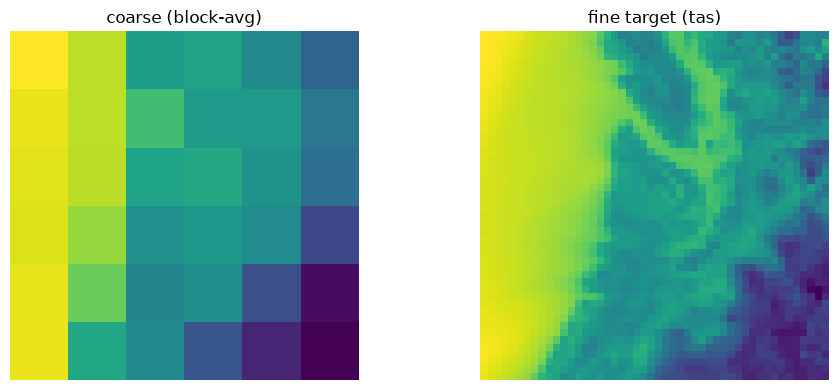

In [10]:
import matplotlib.pyplot as plt
i = 0
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(coarse_stacks[i,0], origin="lower"); ax[0].set_title("coarse (block-avg)")
ax[1].imshow(fine_targets[i],    origin="lower"); ax[1].set_title(f"fine target ({TEMP_VAR})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()